In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Upload Wine.csv to the notebook working folder, or update this path.
df = pd.read_csv("../data\Wine.csv")

print("Shape:", df.shape)
display(df.head())
print("\nDataset information:")
df.info()
print("\nMissing values:")
print(df.isnull().sum())

Shape: (178, 14)


<>:7: SyntaxWarning: invalid escape sequence '\W'
<>:7: SyntaxWarning: invalid escape sequence '\W'
C:\Users\neelp\AppData\Local\Temp\ipykernel_7344\3787636328.py:7: SyntaxWarning: invalid escape sequence '\W'
  df = pd.read_csv("../data\Wine.csv")


,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline,Customer_Segment
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Alcohol               178 non-null    float64
 1   Malic_Acid            178 non-null    float64
 2   Ash                   178 non-null    float64
 3   Ash_Alcanity          178 non-null    float64
 4   Magnesium             178 non-null    int64  
 5   Total_Phenols         178 non-null    float64
 6   Flavanoids            178 non-null    float64
 7   Nonflavanoid_Phenols  178 non-null    float64
 8   Proanthocyanins       178 non-null    float64
 9   Color_Intensity       178 non-null    float64
 10  Hue                   178 non-null    float64
 11  OD280                 178 non-null    float64
 12  Proline               178 non-null    int64  
 13  Customer_Segment      178 non-null    int64  
dtypes: float64(11), int64(3)
memory usage: 19.6 KB

Miss

In [6]:
target_col = "Customer_Segment"   # Change this if your target column has another name

X = df.drop(columns=[target_col])
y = df[target_col]

# Convert categorical input columns into numeric dummy variables, if any
X = pd.get_dummies(X, drop_first=True)

# Encode target labels if they are text
if y.dtype == "object" or str(y.dtype).startswith("category"):
    le = LabelEncoder()
    y = le.fit_transform(y.astype(str))

In [7]:

print("X shape:", X)

X shape:      Alcohol  Malic_Acid   Ash  Ash_Alcanity  Magnesium  Total_Phenols  \
0      14.23        1.71  2.43          15.6        127           2.80   
1      13.20        1.78  2.14          11.2        100           2.65   
2      13.16        2.36  2.67          18.6        101           2.80   
3      14.37        1.95  2.50          16.8        113           3.85   
4      13.24        2.59  2.87          21.0        118           2.80   
..       ...         ...   ...           ...        ...            ...   
173    13.71        5.65  2.45          20.5         95           1.68   
174    13.40        3.91  2.48          23.0        102           1.80   
175    13.27        4.28  2.26          20.0        120           1.59   
176    13.17        2.59  2.37          20.0        120           1.65   
177    14.13        4.10  2.74          24.5         96           2.05   

     Flavanoids  Nonflavanoid_Phenols  Proanthocyanins  Color_Intensity   Hue  \
0          3.06      

In [8]:

print("y shape:", y)

y shape: 0      1
1      1
2      1
3      1
4      1
      ..
173    3
174    3
175    3
176    3
177    3
Name: Customer_Segment, Length: 178, dtype: int64


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (142, 13)
Testing data: (36, 13)


In [ ]:
# Random Forest and the boosting models below are tree-based, so scaling is not necessary.
# Keep the original feature values.

Random Forest (Bagging-based ensemble)

In [10]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        12
           2       1.00      1.00      1.00        14
           3       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



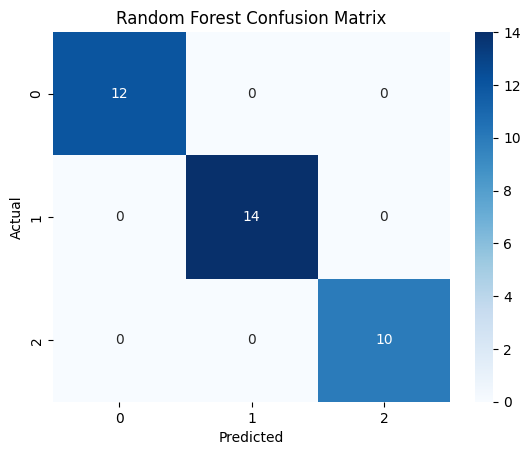

In [13]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues")
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Random Forest feature importance

Color_Intensity    0.187580
Flavanoids         0.159561
Proline            0.146799
Alcohol            0.117913
Hue                0.101538
OD280              0.096301
Total_Phenols      0.041514
Magnesium          0.040131
Malic_Acid         0.033894
Ash_Alcanity       0.025471
dtype: float64


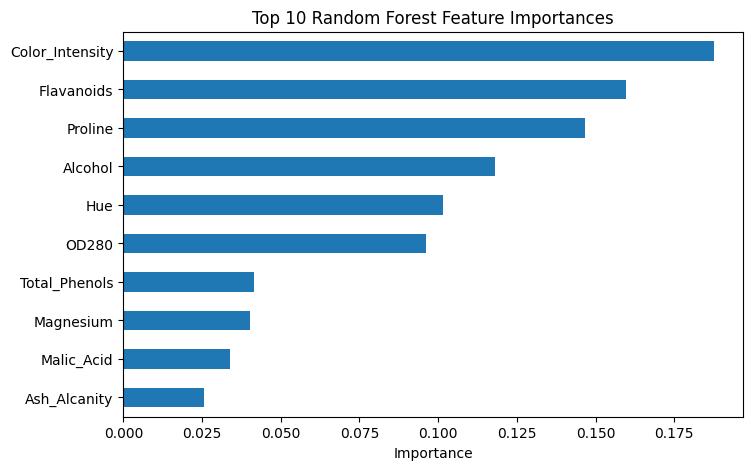

In [14]:
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

print(importance.head(10))
importance.head(10).sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.show()

## Train AdaBoost (Boosting)

In [15]:
ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

ada.fit(X_train, y_train)
y_pred_ada = ada.predict(X_test)

print("AdaBoost Accuracy:", accuracy_score(y_test, y_pred_ada))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_ada))

AdaBoost Accuracy: 0.9722222222222222

Classification Report:
              precision    recall  f1-score   support

           1       0.92      1.00      0.96        12
           2       1.00      0.93      0.96        14
           3       1.00      1.00      1.00        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



## Train Gradient Boosting

In [16]:
gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_test)

print("Gradient Boosting Accuracy:", accuracy_score(y_test, y_pred_gb))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb))

Gradient Boosting Accuracy: 0.9444444444444444

Classification Report:
              precision    recall  f1-score   support

           1       0.92      1.00      0.96        12
           2       0.93      0.93      0.93        14
           3       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.95      0.94      0.95        36
weighted avg       0.95      0.94      0.94        36



## Compare ensemble models

               Model  Accuracy
0      Random Forest  1.000000
1           AdaBoost  0.972222
2  Gradient Boosting  0.944444


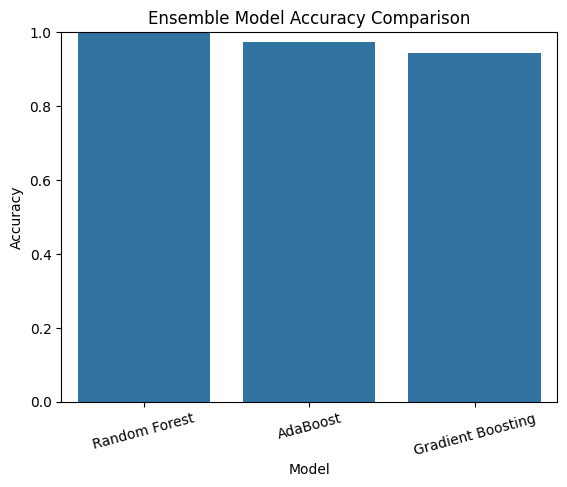

In [17]:
results = pd.DataFrame({
    "Model": ["Random Forest", "AdaBoost", "Gradient Boosting"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_ada),
        accuracy_score(y_test, y_pred_gb)
    ]
})

print(results)
sns.barplot(data=results, x="Model", y="Accuracy")
plt.ylim(0, 1)
plt.title("Ensemble Model Accuracy Comparison")
plt.xticks(rotation=15)
plt.show()

## Analysis / Conclusion

- Random Forest is a bagging-based ensemble: many decision trees are trained using bootstrap samples and their predictions are combined.
- AdaBoost trains weak learners sequentially, giving more attention to observations that were previously misclassified.
- Gradient Boosting adds learners sequentially to reduce the errors of the current ensemble.
- Compare accuracy and the classification reports. The best model is not determined by accuracy alone if the classes are imbalanced.